#Análise de sentimento - Review Spotify

**Problema**:
  Construir um modelo de Deep Learning utilizando as técnicas aprendidas em aula para classificar as avaliações de músicas no Spotify como positivas, neutras ou negativas.


**Dados**:
  Pasta com os datasets: analise-sentimento-spotify
  O conjunto de dados contém avaliações de músicas do Spotify, com as seguintes colunas:


* Time_submitted: Data e horário da avaliação
* Review: Texto da avaliação
* Rating: avaliação da música (de 1 a 5 estrelas)
* Total_thumbsup: Quantidade de curtidas
* Reply: Texto de retorno ao cliente

##Configuração inicial

###Configurando o Drive

###Configurando o diretório

In [3]:
pasta_raiz = '../data/'

###Importando o Pandas

In [4]:
import pandas as pd

###Importanto dataset

In [5]:
df = pd.read_csv(f'{pasta_raiz}/reviews.csv', sep=',',parse_dates=['Time_submitted'])

###Validações simples

In [6]:
df.head(3)

,Time_submitted,Review,Rating,Total_thumbsup,Reply
0,2022-07-09 15:00:00,"Great music service, the audio is high quality...",5,2,NaN
1,2022-07-09 14:21:22,Please ignore previous negative rating. This a...,5,1,NaN
2,2022-07-09 13:27:32,"This pop-up ""Get the best Spotify experience o...",4,0,NaN


In [7]:
df.shape

(61594, 5)

In [8]:
df.dtypes

Time_submitted    datetime64[ns]
Review                    object
Rating                     int64
Total_thumbsup             int64
Reply                     object
dtype: object

##ProfileReport

###Instalando ydata_profiling

In [ ]:
!pip install ydata_profiling

**!!!!!Reiniciar o ambiente!!!!!**

###Importanto ydata_profiling

In [10]:
from ydata_profiling import ProfileReport

###Gerando ProfileReport

In [11]:
profile = ProfileReport(df, title='Reviews Spotify')

###Salvando ProfileReport

In [12]:
profile.to_file(f'{pasta_raiz}/ProfileReport_reviews.html')

/usr/local/lib/python3.10/dist-packages/ydata_profiling/profile_report.py:363: UserWarning: Try running command: 'pip install --upgrade Pillow' to avoid ValueError
  warnings.warn(


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

##Análise Exploratória

###Validando conteúdo das colunas

In [13]:
# Entendendo a temporalidade da coluna Time_submitted
#aproximadamente 6 meses de reviews

min_date = df['Time_submitted'].min()
max_date = df['Time_submitted'].max()
diferenca_datas = max_date - min_date

print("Data mínima:", min_date)
print("Data máxima:", max_date)
print("Diferença entre as datas:", diferenca_datas)

Data mínima: 2022-01-01 00:19:09
Data máxima: 2022-07-09 15:00:00
Diferença entre as datas: 189 days 14:40:51


In [20]:
df.describe()

,Time_submitted,Rating,Total_thumbsup
count,61594,61594.000000,61594.000000
mean,2022-04-20 13:19:59.792544768,3.155989,7.649381
min,2022-01-01 00:19:09,1.000000,0.000000
25%,2022-03-08 20:15:09.249999872,1.000000,0.000000
50%,2022-04-22 02:19:45.500000,3.000000,0.000000
75%,2022-06-03 08:51:11.249999872,5.000000,1.000000
max,2022-07-09 15:00:00,5.000000,8195.000000
std,NaN,1.673285,89.323143


In [ ]:
#Avaliando a nulidade das colunas do DataFrame
#A coluna Reply se destaca pela quantidade de dados faltantes e será ignorada
df.isna().sum()

Time_submitted        0
Review                0
Rating                0
Total_thumbsup        0
Reply             61378
dtype: int64

###Validando a dimensionalidade do dataset

In [ ]:
(
    (
    df[df['Reply'].notnull()]
    .groupby(['Review'])
    .agg(
        qtde_reply = ('Reply','count')
        )
    ).reset_index()
)

,Review,qtde_reply
0,!WARNING! SCAM ALERT! I recently had wished to...,1
1,A bit better with the latest updates. Can find...,1
2,"Ads are fine, if anything they're a necessity....",1
3,After updating the app it removed my downloade...,1
4,Again massive playback dramas following an upd...,1
...,...,...
211,the best music streaming app ever. the sound i...,1
212,the play bar at the bottom of the app keeps di...,1
213,"update, no upgrade. Til Christmas. And beyond....",1
214,£10 a month is *way* too expensive. For that m...,1


**Obs.: O dataset não apresenta mais de uma Reply por Review.
Portanto, a dimensionalidade está a nível de Review**

###Nuvem de Palavras

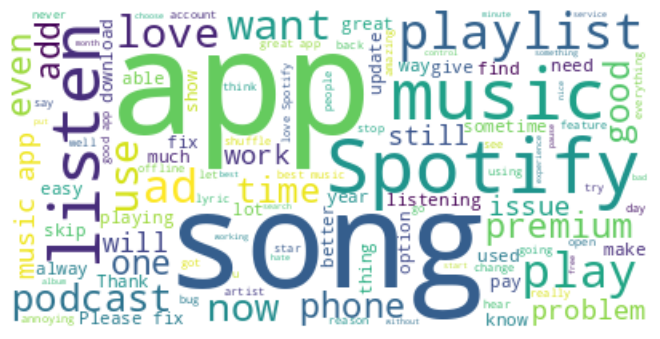

In [22]:
# pega todo o texto da coluna em uma única string
full_text = ' '.join(df["Review"])

# cria o objeto da figura da word cloud
from wordcloud import WordCloud
wc = WordCloud(background_color='white').generate(full_text)

# plota a word cloud
import matplotlib.pyplot as plt

plt.imshow(wc, interpolation='bilinear')
plt.grid('off') # retira grade
plt.axis('off') # retira eixos
plt.tight_layout(pad=0) # ajusta o tamanho

##Processamento de Linguagem Natural

###Instalando e importanto bibliotecas

In [ ]:
!pip install spacy

In [24]:
# Baixando os pacotes do modelo estatístico em ingles (EN)

!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 10.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
!pip install emoji
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import emoji

In [26]:
import spacy
spacy.__version__

'3.7.5'

In [27]:
nlp = spacy.load('en_core_web_sm')

###Classificação da base

In [28]:
# Contagem das avaliações
resumo_ratings = df['Rating'].value_counts().sort_index()

# Exibindo o resumo das avaliações
print("Contagem das Avaliações:")
for rating, count in resumo_ratings.items():
    print(f"Rating {rating}: {count} avaliações")

# Calculando as porcentagens
resumo_ratings_percent = df['Rating'].value_counts(normalize=True).sort_index() * 100

# Exibindo o resumo das avaliações em porcentagens
print("\nPorcentagem das Avaliações:")
for rating, percent in resumo_ratings_percent.items():
    print(f"Rating {rating}: {percent:.2f}%")

Contagem das Avaliações:
Rating 1: 17653 avaliações
Rating 2: 7118 avaliações
Rating 3: 6886 avaliações
Rating 4: 7842 avaliações
Rating 5: 22095 avaliações

Porcentagem das Avaliações:
Rating 1: 28.66%
Rating 2: 11.56%
Rating 3: 11.18%
Rating 4: 12.73%
Rating 5: 35.87%


In [29]:
# Função para atribuir a categoria "POSITIVA", "NEGATIVA" com base na pontuação - 1 e 2 positivo, 3 4 e 5 negativo (visando dar um peso maior às avaliações negativas com o intuito de desenvolvimento de melhorias)
def categorizar_avaliacao(score):
    if score >= 4:
        return "POSITIVA"
    else:
        return "NEGATIVA"

# Aplicar a função à coluna 'Rating' para criar a nova coluna 'avaliacao'
df['avaliacao'] = df['Rating'].apply(categorizar_avaliacao)

# Exibir as primeiras linhas do DataFrame com a nova coluna
df.head()

,Time_submitted,Review,Rating,Total_thumbsup,Reply,avaliacao
0,2022-07-09 15:00:00,"Great music service, the audio is high quality...",5,2,NaN,POSITIVA
1,2022-07-09 14:21:22,Please ignore previous negative rating. This a...,5,1,NaN,POSITIVA
2,2022-07-09 13:27:32,"This pop-up ""Get the best Spotify experience o...",4,0,NaN,POSITIVA
3,2022-07-09 13:26:45,Really buggy and terrible to use as of recently,1,1,NaN,NEGATIVA
4,2022-07-09 13:20:49,Dear Spotify why do I get songs that I didn't ...,1,1,NaN,NEGATIVA


In [30]:
# Contagem das avaliações
resumo_ratings = df['avaliacao'].value_counts().sort_index()

# Exibindo o resumo das avaliações
print("Contagem das Avaliações:")
for rating, count in resumo_ratings.items():
    print(f"Rating {rating}: {count} avaliações")

# Calculando as porcentagens
resumo_ratings_percent = df['avaliacao'].value_counts(normalize=True).sort_index() * 100

# Exibindo o resumo das avaliações em porcentagens
print("\nPorcentagem das Avaliações:")
for rating, percent in resumo_ratings_percent.items():
    print(f"Rating {rating}: {percent:.2f}%")

Contagem das Avaliações:
Rating NEGATIVA: 31657 avaliações
Rating POSITIVA: 29937 avaliações

Porcentagem das Avaliações:
Rating NEGATIVA: 51.40%
Rating POSITIVA: 48.60%


###Carregando stop words

In [31]:
import nltk
stopwords_spacy = spacy.lang.en.stop_words.STOP_WORDS
print(f'Total stopwords: {len(stopwords_spacy)}')
print(stopwords_spacy)
nltk.download('stopwords')
len(nltk.corpus.stopwords.words('english'))
stop_words_final = set(list(stopwords_spacy) + nltk.corpus.stopwords.words('english'))
len(stop_words_final)

Total stopwords: 326
{"'ll", 'was', 'is', 'their', 'between', 'more', 'noone', 'wherein', 'thru', 'say', '’d', 'if', 'five', 'himself', 'either', 'anything', 'yours', 'much', 'so', 'through', 'before', 'n‘t', 'seems', 'our', 'be', 'above', 'have', 'alone', 'when', 'an', 'perhaps', 'the', '‘re', "n't", 'sometime', 'someone', 'last', 'eight', 'everywhere', 'toward', '‘ll', 'seem', 'often', 'whenever', 'both', 'thence', 'back', 'namely', 'ever', 'formerly', 'from', 'into', 'yet', 'indeed', 'each', 'whereupon', 'although', 'herself', 'first', 'quite', 'whence', 'how', 'take', 'four', '’ll', 'really', 'has', 'twenty', 'any', 'his', 'these', 'along', 'done', 'under', 'others', 'will', 'we', 'former', 'can', 'please', 'something', 'only', 'whereby', 'elsewhere', 'itself', 'with', 'move', 'and', 'meanwhile', 'that', 'would', 'not', 'became', 'call', 'latter', 'themselves', 'nobody', 'most', 'about', 'nevertheless', 'while', 'besides', 'also', 'down', 'afterwards', 'by', '’re', 'now', 'every', 

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


382

###Tratando espaço em branco

In [32]:
def contar_sequencias_caracteres_em_branco(texto):
  matches = re.findall(r"\s{2,}", texto)
  return len(matches)

In [33]:
df['total_caracteres_em_branco'] = df['Review'].apply(contar_sequencias_caracteres_em_branco)

In [34]:
def substituir_multiplos_espacos_em_branco(texto):
  return re.sub(r"\s{2,}", " ", texto)

In [35]:
df['Review_sem_espaco'] = df['Review'].apply(substituir_multiplos_espacos_em_branco)

###Processamento

In [ ]:
!pip install pandarallel

In [37]:
import spacy
import emoji
import re
import pandas as pd
from pandarallel import pandarallel
import nltk

# Inicializar pandarallel
pandarallel.initialize(progress_bar=True, nb_workers=8)

# Baixar e carregar stopwords do NLTK
nltk.download('stopwords')
stopwords_nltk = set(nltk.corpus.stopwords.words('english'))

# Carregar stopwords do Spacy
stopwords_spacy = spacy.lang.en.stop_words.STOP_WORDS

# Combinar stopwords do Spacy e NLTK
stop_words_final = stopwords_nltk.union(stopwords_spacy)

# Carregar modelo Spacy fora da função para eficiência
nlp = spacy.load("en_core_web_sm")

# Função de pré-processamento
def preprocessing(texto, stopwords):
    # Deixa o texto em minúsculo
    texto = texto.lower()

    # Substituir tags HTML
    texto = texto.replace('<br />', ' ')

    # Retira nome do usuário (se for rede social): @labdata
    texto = re.sub(r"@[A-Za-z0-9$-_@.&+]+", '', texto)

    # Converter emojis para texto
    texto = emoji.demojize(texto)

    # Retira caracteres especiais
    texto = re.sub(r'\W', ' ', texto)

    # Processar o texto com Spacy
    doc = nlp(texto.strip())

    lista_de_tokens_tratados = []
    for token in doc:
        lemma = token.lemma_.strip()
        if (
            (not token.is_stop) and
            (not token.is_punct) and
            (not token.like_email) and
            (not token.like_url) and
            (lemma not in stopwords)
        ):
            lista_de_tokens_tratados.append(lemma)

    # Esse comando irá recriar a string.
    return ' '.join(lista_de_tokens_tratados)

INFO: Pandarallel will run on 8 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [38]:
# Aplicar a função de pré-processamento
df['Review_processado'] = df['Review_sem_espaco'].parallel_apply(preprocessing, args=(stop_words_final, ))

In [39]:
# Exibir o resultado
df

,Time_submitted,Review,Rating,Total_thumbsup,Reply,avaliacao,total_caracteres_em_branco,Review_sem_espaco,Review_processado
0,2022-07-09 15:00:00,"Great music service, the audio is high quality...",5,2,NaN,POSITIVA,0,"Great music service, the audio is high quality...",great music service audio high quality app ea...
1,2022-07-09 14:21:22,Please ignore previous negative rating. This a...,5,1,NaN,POSITIVA,0,Please ignore previous negative rating. This a...,ignore previous negative rating app super gre...
2,2022-07-09 13:27:32,"This pop-up ""Get the best Spotify experience o...",4,0,NaN,POSITIVA,0,"This pop-up ""Get the best Spotify experience o...",pop good spotify experience android 12 annoy...
3,2022-07-09 13:26:45,Really buggy and terrible to use as of recently,1,1,NaN,NEGATIVA,0,Really buggy and terrible to use as of recently,buggy terrible use recently
4,2022-07-09 13:20:49,Dear Spotify why do I get songs that I didn't ...,1,1,NaN,NEGATIVA,0,Dear Spotify why do I get songs that I didn't ...,dear spotify song playlist shuffle play
...,...,...,...,...,...,...,...,...,...
61589,2022-01-01 03:01:29,Even though it was communicated that lyrics fe...,1,6,NaN,NEGATIVA,0,Even though it was communicated that lyrics fe...,communicate lyric feature available user globa...
61590,2022-01-01 02:13:40,"Use to be sooo good back when I had it, and wh...",1,0,NaN,NEGATIVA,0,"Use to be sooo good back when I had it, and wh...",use sooo good download free version pick so...
61591,2022-01-01 01:02:29,This app would be good if not for it taking ov...,2,10,NaN,NEGATIVA,0,This app would be good if not for it taking ov...,app good device start comp spotify start st...
61592,2022-01-01 00:49:23,The app is good hard to navigate and won't jus...,2,1,NaN,NEGATIVA,0,The app is good hard to navigate and won't jus...,app good hard navigate win let play song click...


In [40]:
df.drop(columns=["Time_submitted"], inplace=True)
df.drop(columns=["Review"], inplace=True)
df.drop(columns=["Rating"], inplace=True)
df.drop(columns=["Total_thumbsup"], inplace=True)
df.drop(columns=["Reply"], inplace=True)
df.drop(columns=["total_caracteres_em_branco"], inplace=True)
df.drop(columns=["Review_sem_espaco"], inplace=True)

In [41]:
df.head(5)

,avaliacao,Review_processado
0,POSITIVA,great music service audio high quality app ea...
1,POSITIVA,ignore previous negative rating app super gre...
2,POSITIVA,pop good spotify experience android 12 annoy...
3,NEGATIVA,buggy terrible use recently
4,NEGATIVA,dear spotify song playlist shuffle play


###Salvando processamento

In [42]:
df.to_csv('../data/df_processado_v3.csv', index=False, encoding='utf-8')
#df.to_csv('../data/df_processado_v3.csv', index=False, encoding='utf-8')

##Treinamento

###Carregamento base processada

In [137]:
pasta_raiz = '../data/'

In [138]:
import pandas as pd
df = pd.read_csv(f'{pasta_raiz}/df_processado_v3.csv', sep=',')

In [139]:
df.head(5)

,avaliacao,Review_processado
0,POSITIVA,great music service audio high quality app ea...
1,POSITIVA,ignore previous negative rating app super gre...
2,POSITIVA,pop good spotify experience android 12 annoy...
3,NEGATIVA,buggy terrible use recently
4,NEGATIVA,dear spotify song playlist shuffle play


###Instalando e importanto bibliotecas

In [140]:
import tensorflow
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, TimeDistributed, CategoryEncoding, Flatten

In [ ]:
!pip install keras-visualizer

###Criando função auxiliar

In [142]:
import numpy as np
import matplotlib.pyplot as plt
from keras_visualizer import visualizer

def plot_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    ax1.plot(history.history['loss'], 'r-', label='train loss')
    ax1.plot(history.history['val_loss'], 'b--', label='test loss')
    ax1.set_title('Model Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')

    ax1.legend()

    ax2.plot(history.history['accuracy'], 'r-', label='train acc')
    ax2.plot(history.history['val_accuracy'], 'b--', label='test acc')
    ax2.set_title('Model Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.tight_layout()

###Modelos

#### Modelo 0 - Redes Recorrentes LSTM com Embedding
Com 10% da base o modelo apresentou acurácia constante em aproximadamente 51%

Provavelmente isso ocorreu pois o max_lengh contem mais de 200 palavras, dificultando a aprendizagem do modelo

In [50]:
# Usando 10% da base, uma vez que a base é grande e demoraria para treinar, tendo atenção na questão da distribuição das classes
# Amostragem estratificada de 10% dos dados
from sklearn.model_selection import train_test_split
df0, _ = train_test_split(df, test_size=0.9, stratify=df['avaliacao'], random_state=42)

In [51]:
df0.shape

(6159, 2)

In [52]:
# Passo 1: Tokenização, gera as palavras
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df0['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df0['Review_token'] = tokenizer.texts_to_sequences(df0['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [56]:
#garantimos que é um array
sequences0 = df0['Review_token']
sequences0 = np.array(sequences0)
print(type(sequences0))

<class 'numpy.ndarray'>


In [57]:
# Passo 2: Padding
max_length0 = max(len(seq) for seq in sequences0)  # Encontra o comprimento máximo entre todas as sequências de números inteiros.
padded_sequences0 = pad_sequences(sequences0, maxlen=max_length0, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [58]:
max_length0

277

In [60]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels0 = df0['avaliacao']
labels0 = np.array(labels0)
labels0

array(['POSITIVA', 'NEGATIVA', 'POSITIVA', ..., 'NEGATIVA', 'POSITIVA',
       'NEGATIVA'], dtype=object)

In [61]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels0 = encoder.fit_transform(labels0)

In [62]:
X_train0, X_test0, y_train0, y_test0 = train_test_split(padded_sequences0, encoded_labels0, test_size=0.2, random_state=42, stratify=encoded_labels0)

In [63]:
print(X_train0.shape)
print(y_train0.shape)
print(X_test0.shape)
print(y_test0.shape)

(4927, 277)
(4927,)
(1232, 277)
(1232,)


In [64]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 8  # Dimensão do vetor de embedding

In [65]:
vocab_size

5696

In [66]:
model_lstm_embedding0 = Sequential()
model_lstm_embedding0.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length0))
model_lstm_embedding0.add(LSTM(units=16))  # Camada LSTM com 16 unidades
model_lstm_embedding0.add(Dense(units=1, activation='sigmoid'))

model_lstm_embedding0.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

hist0 = model_lstm_embedding0.fit(X_train0, y_train0, epochs=10, batch_size=2, validation_split=0.2)

loss0, accuracy0 = model_lstm_embedding0.evaluate(X_test0, y_test0)
print(f'model_lstm_embedding1 - Loss: {loss0:.4f}, Accuracy: {accuracy0:.4f}')

Epoch 1/10
1971/1971 [==============================] - 245s 123ms/step - loss: 0.6932 - accuracy: 0.5133 - val_loss: 0.6933 - val_accuracy: 0.5081
Epoch 2/10
1971/1971 [==============================] - 285s 145ms/step - loss: 0.6932 - accuracy: 0.5108 - val_loss: 0.6933 - val_accuracy: 0.5081
Epoch 3/10
1971/1971 [==============================] - 295s 150ms/step - loss: 0.6929 - accuracy: 0.5138 - val_loss: 0.6933 - val_accuracy: 0.5081
Epoch 4/10
1971/1971 [==============================] - 204s 104ms/step - loss: 0.6930 - accuracy: 0.5154 - val_loss: 0.6932 - val_accuracy: 0.5081
Epoch 5/10
1971/1971 [==============================] - 311s 158ms/step - loss: 0.6930 - accuracy: 0.5154 - val_loss: 0.6930 - val_accuracy: 0.5081
Epoch 6/10
1971/1971 [==============================] - 333s 169ms/step - loss: 0.6929 - accuracy: 0.5154 - val_loss: 0.6930 - val_accuracy: 0.5081
Epoch 7/10
1971/1971 [==============================] - 285s 145ms/step - loss: 0.6929 - accuracy: 0.5154 - val_

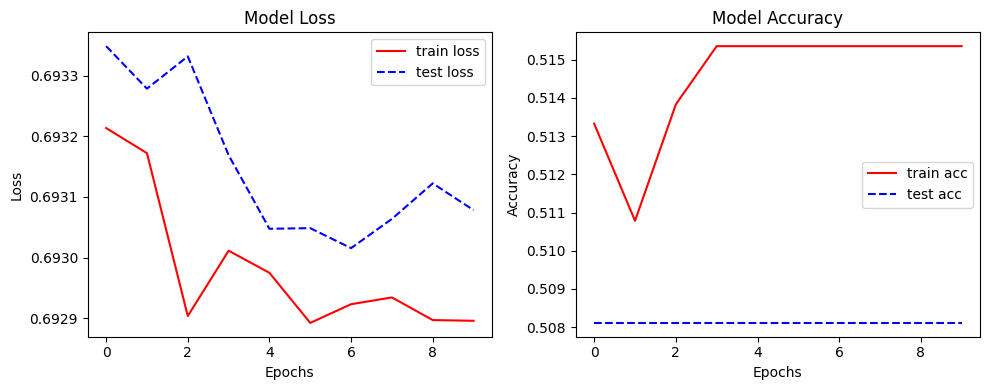

In [68]:
plot_history(hist0)

In [70]:
# Prever as classes para o conjunto de teste
y_train_pred0 = (model_lstm_embedding0.predict(X_train0) > 0.5).astype("int32")
y_test_pred0 = (model_lstm_embedding0.predict(X_test0) > 0.5).astype("int32")

39/39 [==============================] - 1s 34ms/step


In [71]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels0 = encoder.inverse_transform(y_test_pred0.ravel())
y_test_true_labels0 = encoder.inverse_transform(y_test0)
y_train_pred_labels0 = encoder.inverse_transform(y_train_pred0.ravel())
y_train_true_labels0 = encoder.inverse_transform(y_train0)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

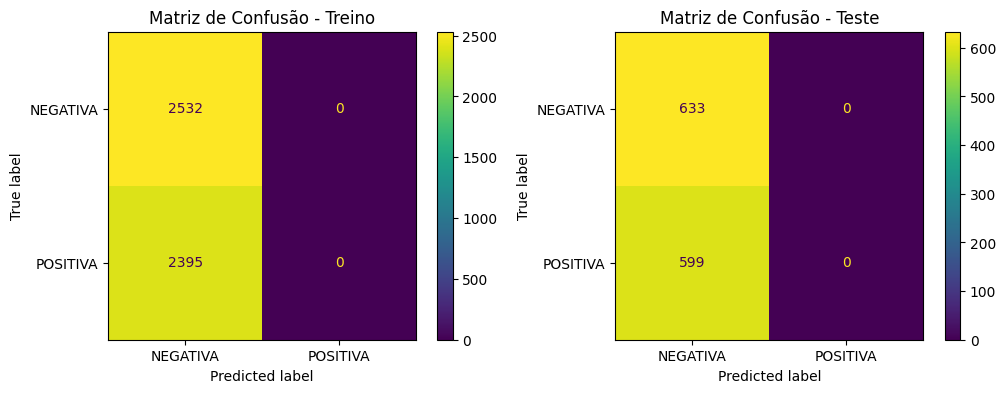

In [73]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig0, axs0 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_true_labels0, y_train_pred_labels0, ax=axs0[0])
axs0[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels0, y_test_pred_labels0, ax=axs0[1])
axs0[1].set_title("Matriz de Confusão - Teste")


#### Modelo 1 - Redes Recorrentes LSTM com Embedding
Foi realizado um estudo encima da quantidade de palavras que compõe a review, com o objetivo de direcionar melhor o treinamento

Notou-se que 75% da base tem no máximo 21 palavras em cada review

Portamos, adotamos 20 palavras como max_length


In [74]:
#Avaliando o total de palavras das reviews
def conta_palavras(text):
    return len(text.strip().split(' '))

# criando algumas variáveis para análise
df = (
    df
    .assign(qtd_palavras_processado = df['Review_processado'].apply(conta_palavras))
)

In [75]:
#75% da base tem no máximo 21 palavras em cada review
df['qtd_palavras_processado'].describe()

count    61594.000000
mean        16.026041
std         12.189903
min          1.000000
25%          7.000000
50%         13.000000
75%         21.000000
max        421.000000
Name: qtd_palavras_processado, dtype: float64

In [76]:
# Usando 10% da base, uma vez que a base é grande e demoraria para treinar, tendo atenção na questão da distribuição das classes
# Amostragem estratificada de 10% dos dados
from sklearn.model_selection import train_test_split
df1, _ = train_test_split(df, test_size=0.9, stratify=df['avaliacao'], random_state=42)

In [77]:
df1.shape

(6159, 3)

In [78]:
# Passo 1: Tokenização, gera as palavras
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df1['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df1['Review_token'] = tokenizer.texts_to_sequences(df1['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [79]:
#garantimos que é um array
sequences1 = df1['Review_token']
sequences1 = np.array(sequences1)
print(type(sequences1))

<class 'numpy.ndarray'>


In [80]:
# Passo 2: Padding
max_length1 = 20 # Definido arbitratiramente 20 palavras visto que 75% das reviews tem até 21 palavras
padded_sequences1 = pad_sequences(sequences1, maxlen=max_length1, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [81]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels1 = df1['avaliacao']
labels1 = np.array(labels1)
labels1

array(['POSITIVA', 'NEGATIVA', 'POSITIVA', ..., 'NEGATIVA', 'POSITIVA',
       'NEGATIVA'], dtype=object)

In [82]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels1 = encoder.fit_transform(labels1)

In [83]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(padded_sequences1, encoded_labels1, test_size=0.2, random_state=42, stratify=encoded_labels1)

In [84]:
print(X_train1.shape)
print(y_train1.shape)
print(X_test1.shape)
print(y_test1.shape)

(4927, 20)
(4927,)
(1232, 20)
(1232,)


In [85]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 8  # Dimensão do vetor de embedding

In [86]:
vocab_size

5696

In [87]:
model_lstm_embedding1 = Sequential()
model_lstm_embedding1.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length1))
model_lstm_embedding1.add(LSTM(units=16))  # Camada LSTM com 16 unidades
model_lstm_embedding1.add(Dense(units=1, activation='sigmoid'))

model_lstm_embedding1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

hist1 = model_lstm_embedding1.fit(X_train1, y_train1, epochs=10, batch_size=2, validation_split=0.2)

loss1, accuracy1 = model_lstm_embedding1.evaluate(X_test1, y_test1)
print(f'model_lstm_embedding2 - Loss: {loss1:.4f}, Accuracy: {accuracy1:.4f}')

Epoch 1/10
1971/1971 [==============================] - 28s 12ms/step - loss: 0.4355 - accuracy: 0.8051 - val_loss: 0.3971 - val_accuracy: 0.8235
Epoch 2/10
1971/1971 [==============================] - 34s 17ms/step - loss: 0.3049 - accuracy: 0.8825 - val_loss: 0.4387 - val_accuracy: 0.8235
Epoch 3/10
1971/1971 [==============================] - 33s 17ms/step - loss: 0.2450 - accuracy: 0.9089 - val_loss: 0.4773 - val_accuracy: 0.8174
Epoch 4/10
1971/1971 [==============================] - 23s 12ms/step - loss: 0.2050 - accuracy: 0.9279 - val_loss: 0.4549 - val_accuracy: 0.8093
Epoch 5/10
1971/1971 [==============================] - 24s 12ms/step - loss: 0.1756 - accuracy: 0.9361 - val_loss: 0.5179 - val_accuracy: 0.7982
Epoch 6/10
1971/1971 [==============================] - 26s 13ms/step - loss: 0.1536 - accuracy: 0.9467 - val_loss: 0.5476 - val_accuracy: 0.8022
Epoch 7/10
1971/1971 [==============================] - 22s 11ms/step - loss: 0.1407 - accuracy: 0.9528 - val_loss: 0.6398 -

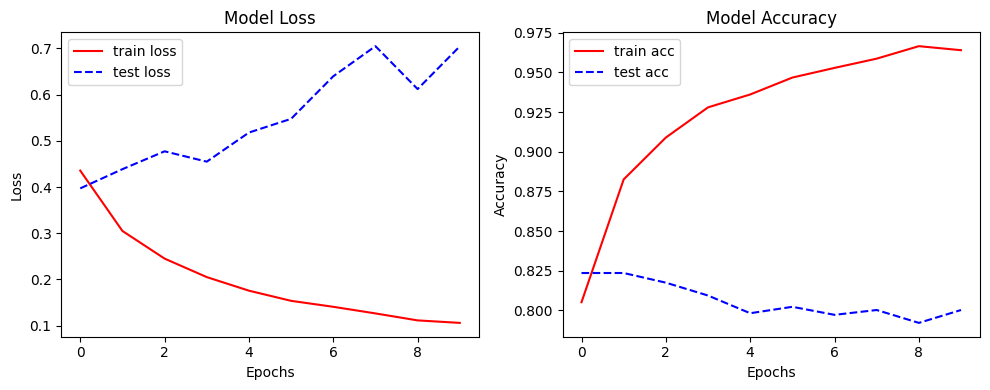

In [88]:
plot_history(hist1)

In [89]:
# Prever as classes para o conjunto de teste
y_train_pred1 = (model_lstm_embedding1.predict(X_train1) > 0.5).astype("int32")
y_test_pred1 = (model_lstm_embedding1.predict(X_test1) > 0.5).astype("int32")

39/39 [==============================] - 0s 3ms/step


In [90]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels1 = encoder.inverse_transform(y_test_pred1.ravel())
y_test_true_labels1 = encoder.inverse_transform(y_test1)
y_train_pred_labels1 = encoder.inverse_transform(y_train_pred1.ravel())
y_train_true_labels1 = encoder.inverse_transform(y_train1)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

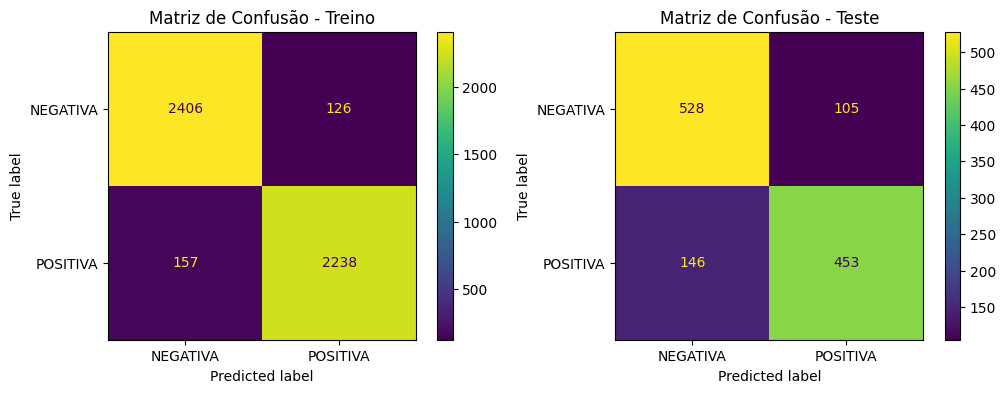

In [91]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig1, axs1 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_true_labels1, y_train_pred_labels1, ax=axs1[0])
axs1[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels1, y_test_pred_labels1, ax=axs1[1])
axs1[1].set_title("Matriz de Confusão - Teste")


#### Modelo 2 - Redes Recorrentes LSTM com Embedding
A performance do modelo melhorou consideravelmente com a redução das palavras inputadas no modelo.

Agora será:
* alterar novamente a quantidade de palavras
* incluída regularização na rede
* aumentada a amostragem para 50% do total dos dados



In [92]:
# Usando 50% da base, uma vez que a base é grande e demoraria para treinar, tendo atenção na questão da distribuição das classes
# Amostragem estratificada de 10% dos dados
from sklearn.model_selection import train_test_split
df2, _ = train_test_split(df, test_size=0.5, stratify=df['avaliacao'], random_state=42)

In [93]:
df2.shape

(30797, 3)

In [94]:
# Passo 1: Tokenização, gera as palavras
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df2['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df2['Review_token'] = tokenizer.texts_to_sequences(df2['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [95]:
#garantimos que é um array
sequences2 = df2['Review_token']
sequences2 = np.array(sequences2)
print(type(sequences2))

<class 'numpy.ndarray'>


In [96]:
# Passo 2: Padding
max_length2 = 25 #Definido arbitratiramente 25 palavras visto que 75% das reviews tem até 21 palavras
padded_sequences2 = pad_sequences(sequences2, maxlen=max_length2, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [97]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels2 = df2['avaliacao']
labels2 = np.array(labels2)
labels2

array(['NEGATIVA', 'POSITIVA', 'NEGATIVA', ..., 'NEGATIVA', 'POSITIVA',
       'NEGATIVA'], dtype=object)

In [98]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels2 = encoder.fit_transform(labels2)

In [99]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(padded_sequences2, encoded_labels2, test_size=0.2, random_state=42, stratify=encoded_labels2)

In [100]:
print(X_train2.shape)
print(y_train2.shape)
print(X_test2.shape)
print(y_test2.shape)

(24637, 25)
(24637,)
(6160, 25)
(6160,)


In [101]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 8  # Dimensão do vetor de embedding

In [102]:
vocab_size

13630

In [103]:
from keras.models import Sequential, load_model
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from keras.regularizers import L1, L2, L1L2

model_lstm_embedding2 = Sequential()
model_lstm_embedding2.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length2,embeddings_regularizer=L2(0.01)))
model_lstm_embedding2.add(LSTM(units=16))  # Camada LSTM com 16 unidades
model_lstm_embedding2.add(Dense(units=1, activation='sigmoid'))

model_lstm_embedding2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

hist2 = model_lstm_embedding2.fit(X_train2, y_train2, epochs=10, batch_size=50, validation_split=0.2)

loss2, accuracy2 = model_lstm_embedding2.evaluate(X_test2, y_test2)
print(f'model_lstm_embedding - Loss: {loss2:.4f}, Accuracy: {accuracy2:.4f}')

Epoch 1/10
395/395 [==============================] - 11s 21ms/step - loss: 0.5187 - accuracy: 0.7802 - val_loss: 0.4064 - val_accuracy: 0.8460
Epoch 2/10
395/395 [==============================] - 6s 15ms/step - loss: 0.4023 - accuracy: 0.8501 - val_loss: 0.4011 - val_accuracy: 0.8509
Epoch 3/10
395/395 [==============================] - 8s 20ms/step - loss: 0.3926 - accuracy: 0.8563 - val_loss: 0.3899 - val_accuracy: 0.8537
Epoch 4/10
395/395 [==============================] - 9s 22ms/step - loss: 0.3891 - accuracy: 0.8560 - val_loss: 0.3918 - val_accuracy: 0.8551
Epoch 5/10
395/395 [==============================] - 6s 15ms/step - loss: 0.3832 - accuracy: 0.8580 - val_loss: 0.3882 - val_accuracy: 0.8537
Epoch 6/10
395/395 [==============================] - 8s 21ms/step - loss: 0.3791 - accuracy: 0.8644 - val_loss: 0.3885 - val_accuracy: 0.8541
Epoch 7/10
395/395 [==============================] - 6s 15ms/step - loss: 0.3749 - accuracy: 0.8634 - val_loss: 0.4002 - val_accuracy: 0.845

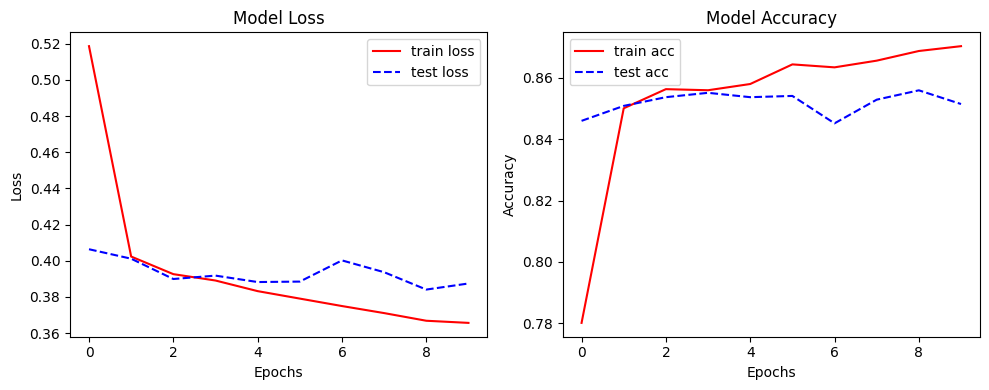

In [104]:
plot_history(hist2)

In [ ]:
# Prever as classes para o conjunto de teste
y_train_pred2 = (model_dense_embedding2.predict(X_train2) > 0.5).astype("int32")
y_test_pred2 = (model_dense_embedding1.predict(X_test2) > 0.5).astype("int32")

193/193 [==============================] - 0s 2ms/step


In [ ]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels2 = encoder.inverse_transform(y_test_pred2.ravel())
y_test_true_labels2 = encoder.inverse_transform(y_test2)
y_train_pred_labels2 = encoder.inverse_transform(y_train_pred2.ravel())
y_train_true_labels2 = encoder.inverse_transform(y_train2)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

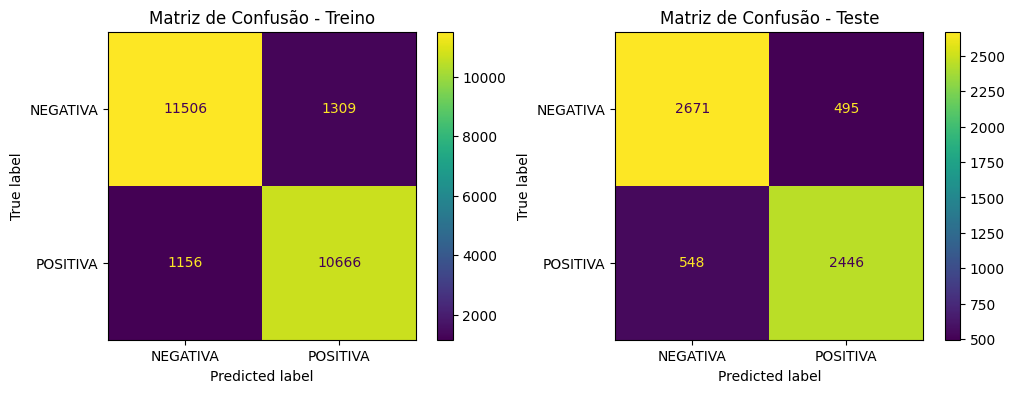

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig2, axs2 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_pred_labels2, y_train_true_labels2, ax=axs2[0])
axs2[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels2, y_test_pred_labels2, ax=axs2[1])
axs2[1].set_title("Matriz de Confusão - Teste")


#### Modelo 3 - Redes Recorrentes LSTM com Embedding
A performance do modelo melhorou consideravelmente com as intervenções anteriores.

Agora será:
* aumentar a dimensão do embedding
* aumentar as épocas
* incluir o early stopping
* incluir o Model Check point



In [105]:
# Usando 50% da base, uma vez que a base é grande e demoraria para treinar, tendo atenção na questão da distribuição das classes
# Amostragem estratificada de 10% dos dados
from sklearn.model_selection import train_test_split
df3, _ = train_test_split(df, test_size=0.5, stratify=df['avaliacao'], random_state=42)

In [106]:
# Passo 1: Tokenização, gera as palavras
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df3['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df3['Review_token'] = tokenizer.texts_to_sequences(df3['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [107]:
#garantimos que é um array
sequences3 = df3['Review_token']
sequences3 = np.array(sequences3)
print(type(sequences3))

<class 'numpy.ndarray'>


In [108]:
# Passo 2: Padding
max_length3 = 25 #Definido arbitratiramente 25 palavras visto que 75% das reviews tem até 21 palavras
padded_sequences3 = pad_sequences(sequences3, maxlen=max_length3, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [109]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels3 = df3['avaliacao']
labels3 = np.array(labels3)
labels3

array(['NEGATIVA', 'POSITIVA', 'NEGATIVA', ..., 'NEGATIVA', 'POSITIVA',
       'NEGATIVA'], dtype=object)

In [110]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels3 = encoder.fit_transform(labels3)

In [111]:
X_train3, X_test3, y_train3, y_test3 = train_test_split(padded_sequences3, encoded_labels3, test_size=0.2, random_state=42, stratify=encoded_labels3)

In [112]:
print(X_train3.shape)
print(y_train3.shape)
print(X_test3.shape)
print(y_test3.shape)

(24637, 25)
(24637,)
(6160, 25)
(6160,)


In [113]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 16  # Dimensão do vetor de embedding

In [114]:
from keras.models import Sequential, load_model
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from keras.regularizers import L1, L2, L1L2
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint

model_lstm_embedding3 = Sequential()
model_lstm_embedding3.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length3,embeddings_regularizer=L2(0.01)))
model_lstm_embedding3.add(LSTM(units=16))  # Camada LSTM com 16 unidades
model_lstm_embedding3.add(Dense(units=1, activation='sigmoid'))

model_lstm_embedding3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stopping3 = EarlyStopping(monitor='val_loss', patience=5)
callbacks3 = [ModelCheckpoint(filepath='review_lstm.keras', save_best_only=True)]

hist3 = model_lstm_embedding3.fit(X_train3, y_train3, epochs=20, batch_size=2, validation_split=0.2)

loss3, accuracy3 = model_lstm_embedding3.evaluate(X_test3, y_test3)
print(f'model_lstm_embedding - Loss: {loss3:.4f}, Accuracy: {accuracy3:.4f}')

Epoch 1/20
9855/9855 [==============================] - 196s 20ms/step - loss: 0.4965 - accuracy: 0.8131 - val_loss: 0.4292 - val_accuracy: 0.8458
Epoch 2/20
9855/9855 [==============================] - 168s 17ms/step - loss: 0.4391 - accuracy: 0.8404 - val_loss: 0.4180 - val_accuracy: 0.8458
Epoch 3/20
9855/9855 [==============================] - 168s 17ms/step - loss: 0.4222 - accuracy: 0.8447 - val_loss: 0.4062 - val_accuracy: 0.8506
Epoch 4/20
9855/9855 [==============================] - 171s 17ms/step - loss: 0.4184 - accuracy: 0.8439 - val_loss: 0.4206 - val_accuracy: 0.8405
Epoch 5/20
9855/9855 [==============================] - 168s 17ms/step - loss: 0.4146 - accuracy: 0.8453 - val_loss: 0.4512 - val_accuracy: 0.8131
Epoch 6/20
9855/9855 [==============================] - 171s 17ms/step - loss: 0.4164 - accuracy: 0.8447 - val_loss: 0.4151 - val_accuracy: 0.8484
Epoch 7/20
9855/9855 [==============================] - 171s 17ms/step - loss: 0.4166 - accuracy: 0.8477 - val_loss: 0

In [134]:
model_lstm_embedding3.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_3 (Embedding)     (None, 25, 16)            218080    
                                                                 
 lstm_3 (LSTM)               (None, 16)                2112      
                                                                 
 dense_3 (Dense)             (None, 1)                 17        
                                                                 
Total params: 220209 (860.19 KB)
Trainable params: 220209 (860.19 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


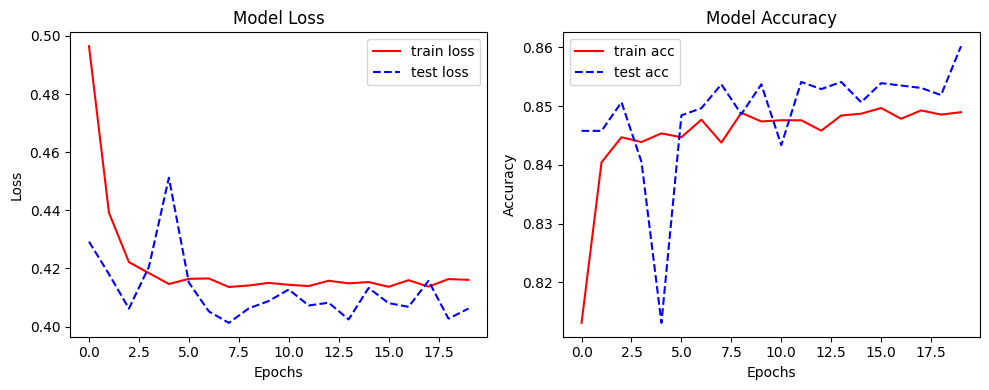

In [118]:
plot_history(hist3)

In [210]:
# Prever as classes para o conjunto de teste
y_train_pred3 = (model_lstm_embedding3.predict(X_train3) > 0.5).astype("int32")
y_test_pred3 = (model_lstm_embedding3.predict(X_test3) > 0.5).astype("int32")

193/193 [==============================] - 1s 6ms/step


In [211]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels3 = encoder.inverse_transform(y_test_pred3.ravel())
y_test_true_labels3 = encoder.inverse_transform(y_test3)
y_train_pred_labels3 = encoder.inverse_transform(y_train_pred3.ravel())
y_train_true_labels3 = encoder.inverse_transform(y_train3)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

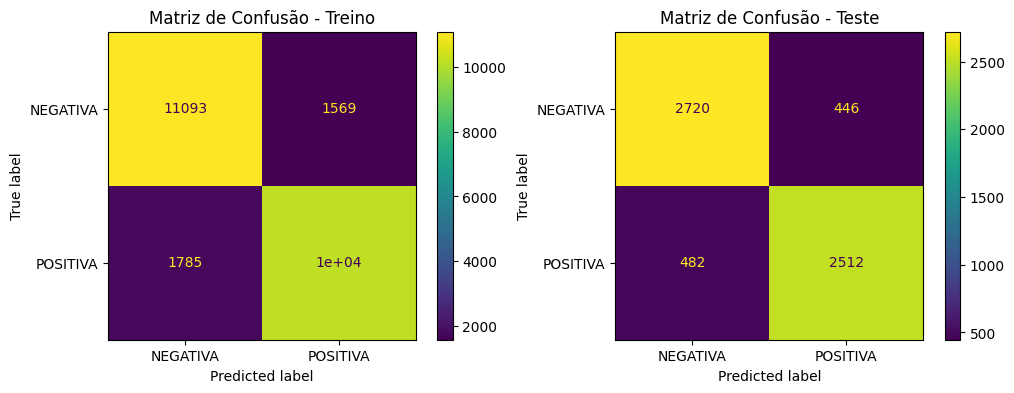

In [212]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig3, axs3 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_true_labels3, y_train_pred_labels3, ax=axs3[0])
axs3[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels3, y_test_pred_labels3, ax=axs3[1])
axs3[1].set_title("Matriz de Confusão - Teste")


#### Modelo 4 - Redes Recorrentes LSTM com Embedding
A performance do modelo não melhorou consideravelmente com as intervenções anteriores.
Será:
* aumentar dados
* reduzir as épocas
* reduzir batch size
* manter o early stopping
* manter o Model Check point



In [194]:
# Passo 1: Tokenização, gera as palavras
df4 = pd.DataFrame()
df4 = df
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df4['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df4['Review_token'] = tokenizer.texts_to_sequences(df4['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [195]:
df4.shape

(61594, 3)

In [196]:
#garantimos que é um array
sequences4 = df4['Review_token']
sequences4 = np.array(sequences4)
print(type(sequences4))

<class 'numpy.ndarray'>


In [197]:
# Passo 2: Padding
max_length4 = 25 #Definido arbitratiramente 25 palavras visto que 75% das reviews tem até 21 palavras
padded_sequences4 = pad_sequences(sequences4, maxlen=max_length4, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [198]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels4 = df4['avaliacao']
labels4 = np.array(labels4)
labels4

array(['POSITIVA', 'POSITIVA', 'POSITIVA', ..., 'NEGATIVA', 'NEGATIVA',
       'POSITIVA'], dtype=object)

In [199]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels4 = encoder.fit_transform(labels4)

In [200]:
X_train4, X_test4, y_train4, y_test4 = train_test_split(padded_sequences4, encoded_labels4, test_size=0.2, random_state=42, stratify=encoded_labels4)

In [201]:
print(X_train4.shape)
print(y_train4.shape)
print(X_test4.shape)
print(y_test4.shape)

(49275, 25)
(49275,)
(12319, 25)
(12319,)


In [202]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 16  # Dimensão do vetor de embedding

In [203]:
vocab_size

20021

In [204]:
from keras.models import Sequential, load_model
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from keras.regularizers import L1, L2, L1L2

model_lstm_embedding4 = Sequential()
model_lstm_embedding4.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length4,embeddings_regularizer=L2(0.01)))
model_lstm_embedding4.add(LSTM(units=16))  # Camada LSTM com 16 unidades
model_lstm_embedding4.add(Dense(units=1, activation='sigmoid'))

model_lstm_embedding4.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

from keras.callbacks import EarlyStopping

early_stopping4 = EarlyStopping(monitor='val_loss', patience=5)

from keras.callbacks import ModelCheckpoint

callbacks4 = [ModelCheckpoint(filepath='review_lstm.keras', save_best_only=True)]

hist4 = model_lstm_embedding4.fit(X_train4, y_train4, epochs=10, batch_size=1, validation_split=0.2)

loss4, accuracy4 = model_lstm_embedding4.evaluate(X_test4, y_test4)
print(f'model_lstm_embedding - Loss: {loss4:.4f}, Accuracy: {accuracy4:.4f}')

Epoch 1/10
39420/39420 [==============================] - 620s 16ms/step - loss: 0.4711 - accuracy: 0.8245 - val_loss: 0.4182 - val_accuracy: 0.8459
Epoch 2/10
39420/39420 [==============================] - 617s 16ms/step - loss: 0.4329 - accuracy: 0.8387 - val_loss: 0.4167 - val_accuracy: 0.8505
Epoch 3/10
39420/39420 [==============================] - 602s 15ms/step - loss: 0.4291 - accuracy: 0.8403 - val_loss: 0.4174 - val_accuracy: 0.8453
Epoch 4/10
39420/39420 [==============================] - 615s 16ms/step - loss: 0.4290 - accuracy: 0.8411 - val_loss: 0.4268 - val_accuracy: 0.8465
Epoch 5/10
39420/39420 [==============================] - 632s 16ms/step - loss: 0.4270 - accuracy: 0.8425 - val_loss: 0.4121 - val_accuracy: 0.8522
Epoch 6/10
39420/39420 [==============================] - 640s 16ms/step - loss: 0.4264 - accuracy: 0.8438 - val_loss: 0.4187 - val_accuracy: 0.8463
Epoch 7/10
39420/39420 [==============================] - 666s 17ms/step - loss: 0.4271 - accuracy: 0.8445

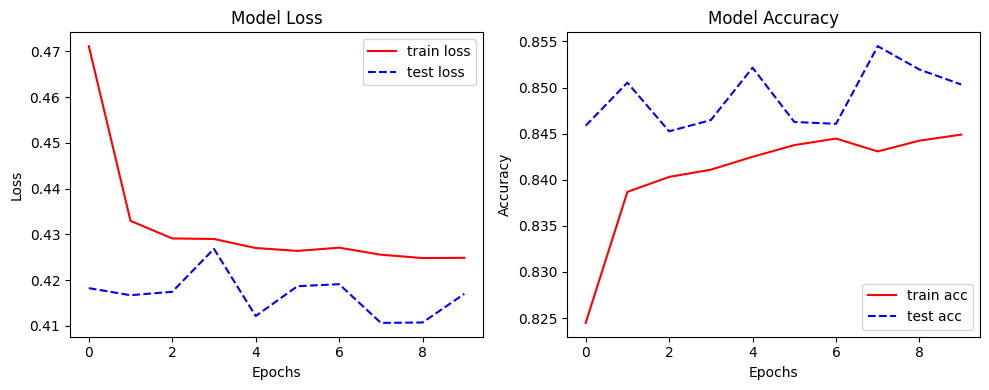

In [205]:
plot_history(hist4)

In [207]:
# Prever as classes para o conjunto de teste
y_train_pred4 = (model_lstm_embedding4.predict(X_train4) > 0.5).astype("int32")
y_test_pred4 = (model_lstm_embedding4.predict(X_test4) > 0.5).astype("int32")

385/385 [==============================] - 2s 6ms/step


In [208]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels4 = encoder.inverse_transform(y_test_pred4.ravel())
y_test_true_labels4 = encoder.inverse_transform(y_test4)
y_train_pred_labels4 = encoder.inverse_transform(y_train_pred4.ravel())
y_train_true_labels4 = encoder.inverse_transform(y_train4)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

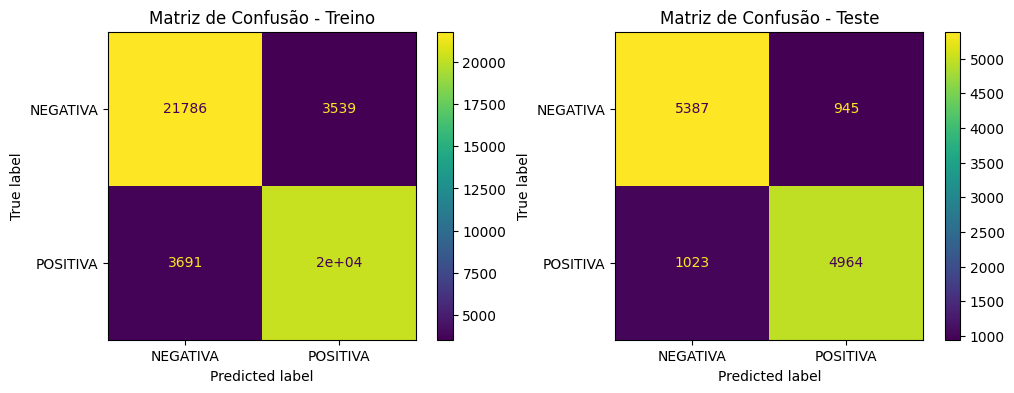

In [209]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig4, axs4 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_true_labels4, y_train_pred_labels4, ax=axs4[0])
axs4[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels4, y_test_pred_labels4, ax=axs4[1])
axs4[1].set_title("Matriz de Confusão - Teste")


#### Modelo 5 - Redes Densas com Embedding
* embedding 16
* 20 épocas
* incluir o early stopping
* incluir o Model Check point
* incluir regularização L2


In [178]:
# Usando 50% da base, uma vez que a base é grande e demoraria para treinar, tendo atenção na questão da distribuição das classes
from sklearn.model_selection import train_test_split
df5, _ = train_test_split(df, test_size=0.5, stratify=df['avaliacao'], random_state=42)

In [179]:
df5.shape

(30797, 2)

In [180]:
# Passo 1: Tokenização, gera as palavras
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df5['Review_processado']) #Treina o Tokenizer no conjunto de frases.
df5['Review_token'] = tokenizer.texts_to_sequences(df5['Review_processado'])#  Converte as frases em sequências de números inteiros com base no vocabulário criado pelo Tokenizer.

In [181]:
#garantimos que é um array
sequences5 = df5['Review_token']
sequences5 = np.array(sequences5)
print(type(sequences5))

<class 'numpy.ndarray'>


In [182]:
# Passo 2: Padding
max_length5 = 25 #Definido arbitratiramente 25 palavras visto que 75% das reviews tem até 21 palavras
padded_sequences5 = pad_sequences(sequences5, maxlen=max_length5, padding='post') # Aplica padding nas sequências para que todas tenham o mesmo comprimento (max_length), preenchendo no final da sequência.

In [183]:
# Passo 3: Codificação dos rótulos
# Rótulos correspondentes para as frases (0 = negativo, 1 = positivo)
labels5 = df5['avaliacao']
labels5 = np.array(labels5)
labels5

array(['NEGATIVA', 'POSITIVA', 'NEGATIVA', ..., 'NEGATIVA', 'POSITIVA',
       'NEGATIVA'], dtype=object)

In [184]:
from sklearn.preprocessing import LabelEncoder
# Encode as labels
encoder = LabelEncoder()
encoded_labels5 = encoder.fit_transform(labels5)

In [185]:
X_train5, X_test5, y_train5, y_test5 = train_test_split(padded_sequences5, encoded_labels5, test_size=0.2, random_state=42, stratify=encoded_labels5)

In [186]:
print(X_train5.shape)
print(y_train5.shape)
print(X_test5.shape)
print(y_test5.shape)

(24637, 25)
(24637,)
(6160, 25)
(6160,)


In [187]:
vocab_size = len(tokenizer.word_index) + 1  # Calcula o tamanho do vocabulário, adicionando 1 para incluir o índice zero reservado para padding.
embedding_dim = 16  # Dimensão do vetor de embedding

In [188]:
vocab_size

13630

In [189]:
from keras.models import Sequential, load_model
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout
from keras.regularizers import L1, L2, L1L2
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint

# Modelo Denso (MLP)
model_dense_embedding5 = Sequential()
model_dense_embedding5.add(Input(shape=(max_length5, 1)))
model_dense_embedding5.add(Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length5,embeddings_regularizer=L2(0.01)))
model_dense_embedding5.add(Flatten())  # Achatar a saída para entrada na camada densa
model_dense_embedding5.add(Dense(units=64, activation='relu'))
model_dense_embedding5.add(Dense(units=32, activation='relu'))
model_dense_embedding5.add(Dense(units=1, activation='sigmoid'))

# Compilação do modelo
model_dense_embedding5.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping e Model Checkpoint
early_stopping5 = EarlyStopping(monitor='val_loss', patience=5)
callbacks5 = [ModelCheckpoint(filepath='review_lstm.keras', save_best_only=True)]

# Treinamento do modelo
hist5 = model_dense_embedding5.fit(X_train5, y_train5, epochs=20, batch_size=2, validation_split=0.2)

# Avaliação do modelo
loss5, accuracy5 = model_dense_embedding5.evaluate(X_test5, y_test5)
print(f'model_dense_embedding0: {loss5:.4f}, Accuracy: {accuracy5:.4f}')

Epoch 1/20
9855/9855 [==============================] - 102s 10ms/step - loss: 0.5045 - accuracy: 0.8216 - val_loss: 0.4793 - val_accuracy: 0.8393
Epoch 2/20
9855/9855 [==============================] - 59s 6ms/step - loss: 0.4812 - accuracy: 0.8355 - val_loss: 0.4720 - val_accuracy: 0.8364
Epoch 3/20
9855/9855 [==============================] - 61s 6ms/step - loss: 0.4778 - accuracy: 0.8410 - val_loss: 0.4775 - val_accuracy: 0.8419
Epoch 4/20
9855/9855 [==============================] - 64s 7ms/step - loss: 0.4736 - accuracy: 0.8448 - val_loss: 0.4804 - val_accuracy: 0.8409
Epoch 5/20
9855/9855 [==============================] - 62s 6ms/step - loss: 0.4720 - accuracy: 0.8464 - val_loss: 0.4725 - val_accuracy: 0.8454
Epoch 6/20
9855/9855 [==============================] - 68s 7ms/step - loss: 0.4699 - accuracy: 0.8474 - val_loss: 0.4853 - val_accuracy: 0.8385
Epoch 7/20
9855/9855 [==============================] - 60s 6ms/step - loss: 0.4698 - accuracy: 0.8522 - val_loss: 0.5220 - val_

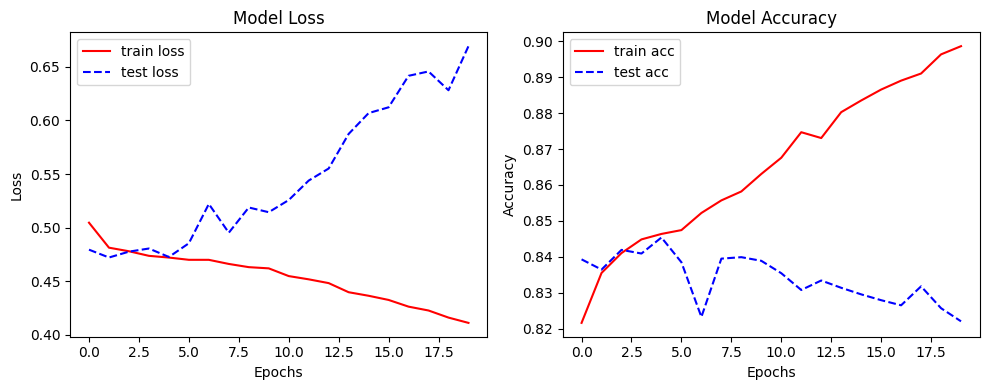

In [190]:
plot_history(hist5)

In [191]:
# Prever as classes para o conjunto de teste
y_train_pred5 = (model_dense_embedding5.predict(X_train5) > 0.5).astype("int32")
y_test_pred5 = (model_dense_embedding5.predict(X_test5) > 0.5).astype("int32")

193/193 [==============================] - 1s 5ms/step


In [192]:
# Transformar de volta para rótulos originais, se necessário
y_test_pred_labels5 = encoder.inverse_transform(y_test_pred5.ravel())
y_test_true_labels5 = encoder.inverse_transform(y_test5)
y_train_pred_labels5 = encoder.inverse_transform(y_train_pred5.ravel())
y_train_true_labels5 = encoder.inverse_transform(y_train5)

Text(0.5, 1.0, 'Matriz de Confusão - Teste')

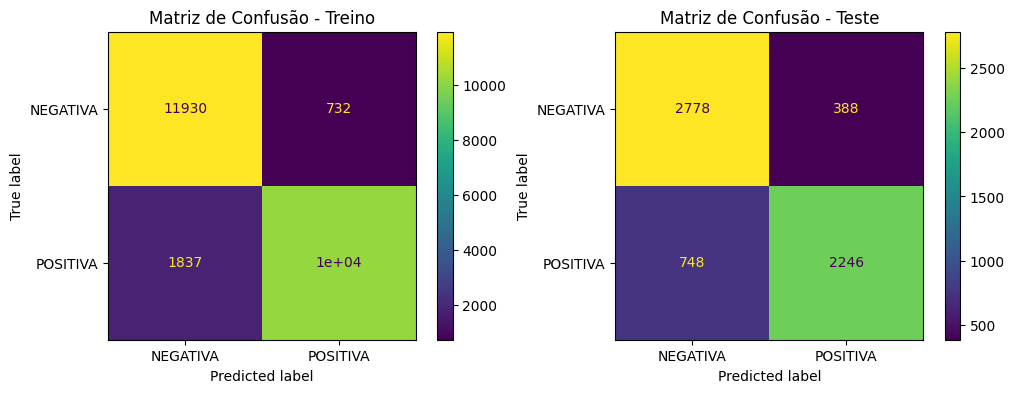

In [213]:
from sklearn.metrics import ConfusionMatrixDisplay
# Plotar a matriz de confusão

fig5, axs5 = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_train_true_labels5, y_train_pred_labels5, ax=axs5[0])
axs5[0].set_title("Matriz de Confusão - Treino")

ConfusionMatrixDisplay.from_predictions(y_test_true_labels5, y_test_pred_labels5, ax=axs5[1])
axs5[1].set_title("Matriz de Confusão - Teste")
